# 📡 Customer Churn Predictor
**PSEB Artificial Intelligence Bootcamp | Business ML Activity**

**Business problem:** A telecom company loses customers every month. Keeping a customer costs far less than finding a new one.
**Goal:** (1) find out *why* customers leave, (2) build a model that predicts *who* will leave, (3) give the team a live tool.

**Dataset:** Telco Customer Churn (Kaggle), 7,043 customers and 21 columns. The target column is `Churn` (Yes / No).

## Step 1: Load the data
In Colab, upload `telco_churn.csv` when asked. On your own computer, keep the file next to this notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

try:
    df = pd.read_csv("telco_churn.csv")
except FileNotFoundError:
    from google.colab import files      # only works inside Google Colab
    files.upload()                      # choose telco_churn.csv
    df = pd.read_csv("telco_churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 2: First look
Check the size, the data types, missing values and duplicates *before* modelling.

In [2]:
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())
print()
df.info()

Shape: (7043, 21)
Duplicate rows: 0
Duplicate customer IDs: 0

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str

In [3]:
print("Churn split:")
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

Churn split:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


**What we found**
- 7,043 rows, 21 columns, no duplicates.
- `TotalCharges` is stored as **text** (object), although it should be a number.
- Only about **26.5%** of customers churn. The classes are *imbalanced*, so accuracy alone will be misleading. We must watch **recall**.

## Step 3: Clean the data
`TotalCharges` has hidden blank values (a space `' '`). `pd.to_numeric(errors="coerce")` turns them into NaN so we can see them.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head()

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN


All 11 blank rows have `tenure = 0`: these are brand-new customers who have not been billed yet. So their real total is **0**, and we fill with 0. `customerID` is just a label, so we drop it.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")

# Churn as 0/1 for easy maths (1 = customer left)
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Missing values left:", df.isna().sum().sum())
df.shape

Missing values left: 0


(7043, 21)

## Step 4: Exploratory Data Analysis (EDA)
This is the part managers care about: **why** do customers leave?

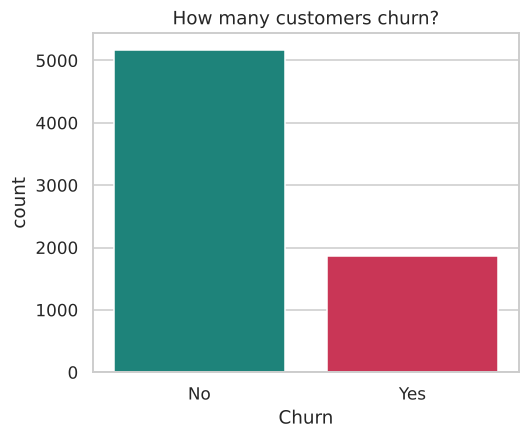

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#0d9488", "#e11d48"], legend=False, ax=ax)
ax.set_title("How many customers churn?")
plt.show()

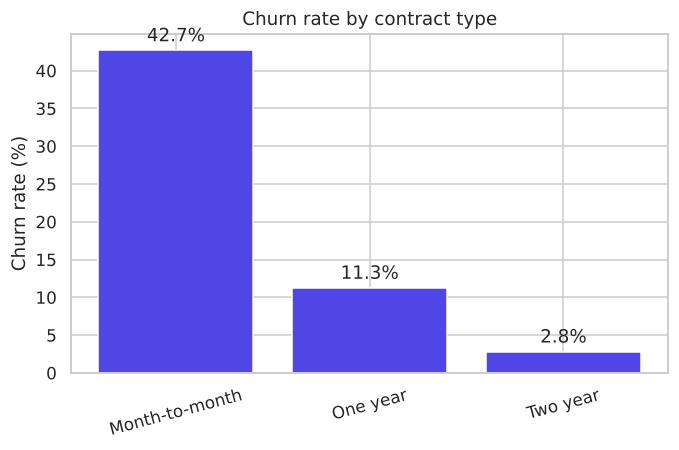

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: ChurnFlag, dtype: float64

In [7]:
def churn_rate_plot(column, title, order=None):
    rate = df.groupby(column)["ChurnFlag"].mean().mul(100)
    if order: rate = rate.reindex(order)
    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(rate.index, rate.values, color="#4f46e5")
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
    ax.set_ylabel("Churn rate (%)"); ax.set_title(title)
    plt.xticks(rotation=15); plt.show()
    return rate

churn_rate_plot("Contract", "Churn rate by contract type")

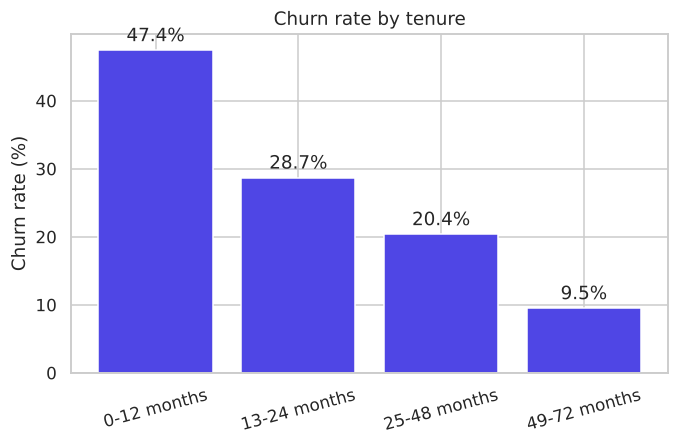

TenureGroup
0-12 months     47.438243
13-24 months    28.710938
25-48 months    20.388959
49-72 months     9.513176
Name: ChurnFlag, dtype: float64

In [8]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                           labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
churn_rate_plot("TenureGroup", "Churn rate by tenure")

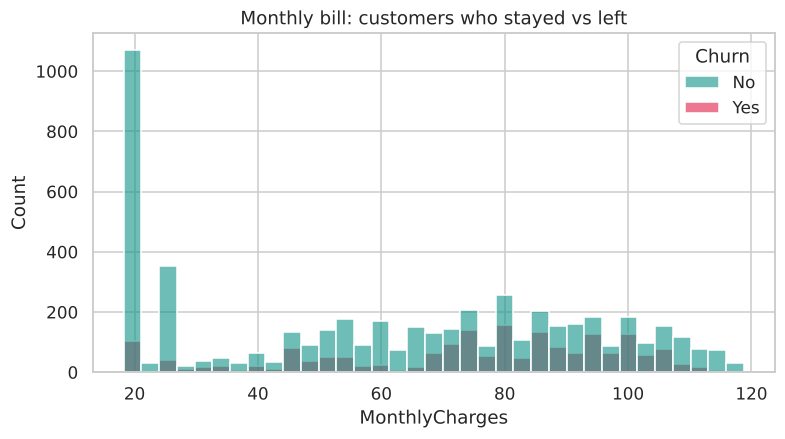

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=35, multiple="layer",
             palette={"No": "#0d9488", "Yes": "#e11d48"}, alpha=0.6, ax=ax)
ax.set_title("Monthly bill: customers who stayed vs left")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean().round(2))

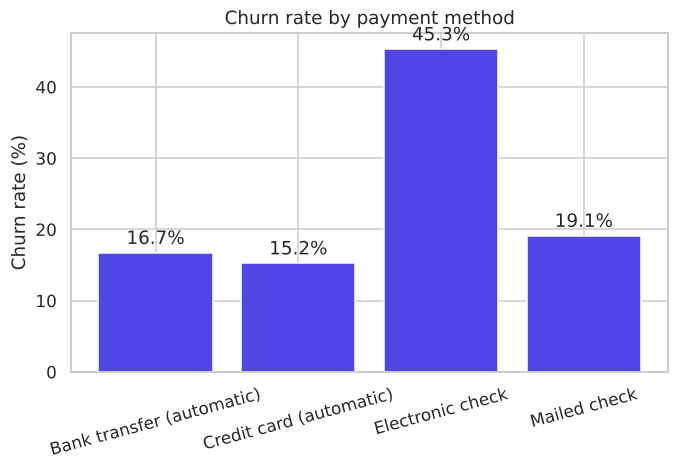

PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: ChurnFlag, dtype: float64

In [10]:
churn_rate_plot("PaymentMethod", "Churn rate by payment method")

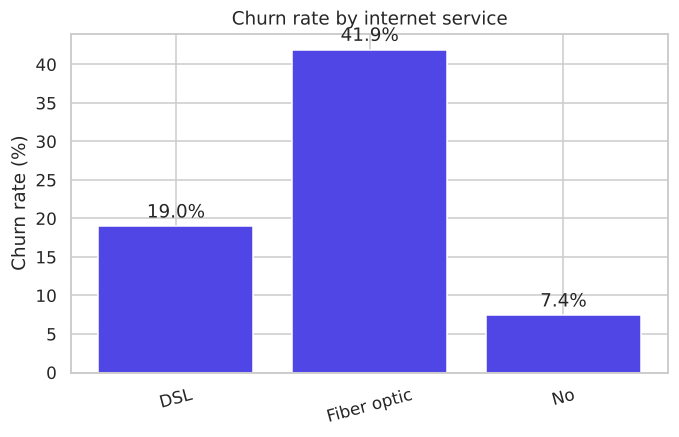


Churn rate when the customer has NO tech support vs has it (internet users only):
TechSupport
No     41.6
Yes    15.2
Name: ChurnFlag, dtype: float64


In [11]:
churn_rate_plot("InternetService", "Churn rate by internet service")
print()
print("Churn rate when the customer has NO tech support vs has it (internet users only):")
net = df[df["InternetService"] != "No"]
print((net.groupby("TechSupport")["ChurnFlag"].mean() * 100).round(1))

### EDA findings
- **Contract:** month-to-month customers churn at about **43%**, one-year about 11%, two-year only about **3%**.
- **Tenure:** most churn happens in the **first year**. Customers who stay past two years rarely leave.
- **Monthly bill:** customers who left pay more on average (about $74 vs $61).
- **Payment method:** electronic check users churn at about **45%**, far above automatic payments (about 15-17%).
- **Internet service:** fiber optic customers churn at about 42%, and customers without tech support churn much more.

## Step 5: Prepare the data (80/20 split)
`stratify=y` keeps the same 26.5% churn ratio in both the training and test sets. `random_state=42` makes the result repeatable.

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "ChurnFlag", "TenureGroup"])
y = df["ChurnFlag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean() * 100, 1), "%")
print("Churn rate test: ", round(y_test.mean() * 100, 1), "%")

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 26.5 %
Churn rate test:  26.5 %


## Step 6: Build the preprocessing pipeline
- **Numbers** (`tenure`, `MonthlyCharges`, `TotalCharges`) → `StandardScaler`
- **Categories** (everything else, e.g. Contract) → `OneHotEncoder`

Putting this in a pipeline means the *same* steps run on training data, test data and the app's inputs, with no data leakage.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])
print("Numeric columns:", numeric_cols)
print("Categorical columns:", len(categorical_cols))

Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: 16


## Step 7: Compare three algorithms
We train Logistic Regression, Decision Tree and Random Forest with default settings and compare them.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(models):
    rows = {}
    for name, model in models.items():
        pipe = Pipeline([("prep", preprocess), ("model", model)])
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        rows[name] = {
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
        }
    return pd.DataFrame(rows).T.round(3)

plain_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
}
results_plain = evaluate(plain_models)
results_plain

,Accuracy,Precision,Recall,F1
Logistic Regression,0.806,0.657,0.559,0.604
Decision Tree,0.718,0.470,0.479,0.474
Random Forest,0.782,0.613,0.487,0.542


Accuracy looks fine (about 72-81%), but **recall is low** (48-56%): the models miss about half of the customers who leave. That is the problem we fix next.

## Step 8: Focus on recall with `class_weight="balanced"`
A missed churner is a lost customer, so catching leavers matters most. `class_weight="balanced"` tells the model that a mistake on a churner costs more than a mistake on a loyal customer.

In [15]:
balanced_models = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree (balanced)": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest (balanced)": RandomForestClassifier(class_weight="balanced", random_state=42),
}
results_balanced = evaluate(balanced_models)
results_balanced

,Accuracy,Precision,Recall,F1
Logistic Regression (balanced),0.738,0.504,0.783,0.614
Decision Tree (balanced),0.727,0.487,0.489,0.488
Random Forest (balanced),0.765,0.551,0.618,0.583


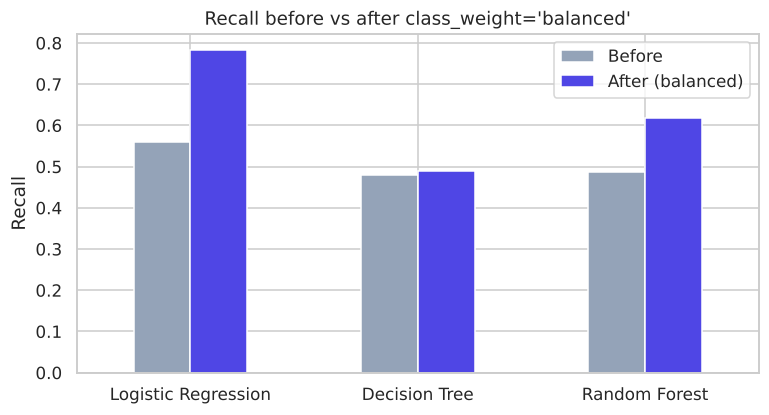

,Before,After (balanced)
Logistic Regression,0.559,0.783
Decision Tree,0.479,0.489
Random Forest,0.487,0.618


In [16]:
# Recall: before vs after balancing
compare = pd.DataFrame({
    "Before": results_plain["Recall"].values,
    "After (balanced)": results_balanced["Recall"].values,
}, index=["Logistic Regression", "Decision Tree", "Random Forest"])

ax = compare.plot(kind="bar", figsize=(8, 4), color=["#94a3b8", "#4f46e5"])
ax.set_ylabel("Recall"); ax.set_title("Recall before vs after class_weight='balanced'")
plt.xticks(rotation=0); plt.show()
compare.round(3)

Balancing raises recall a lot, most clearly for Logistic Regression (about 56% → 78%). Precision drops, which is the expected trade-off.

**Why we continue with Random Forest:** it can be tuned with settings such as tree depth, which controls overfitting, and it also gives us feature importances to explain *why* customers leave. The tuning in the next step lifts its recall to the level of the best simple model. Logistic Regression is a strong, simpler alternative.

## Step 9: Tune the Random Forest with GridSearchCV
GridSearchCV tries every combination of settings using 5-fold cross-validation and keeps the one with the best **recall**. This takes about a minute.

In [17]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(class_weight="balanced", random_state=42)),
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(pipe, param_grid, scoring="recall", cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated recall:", round(grid.best_score_, 3))
best_model = grid.best_estimator_

Best settings: {'model__max_depth': 5, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}
Best cross-validated recall: 0.809


A shallow forest (`max_depth=5`) with larger leaves (`min_samples_leaf=10`) wins. Simpler trees generalise better here because deep trees memorise the training data.

## Step 10: Evaluate on unseen test data
The test set was never used for training or tuning, so these scores show how the model behaves on new customers.

In [18]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



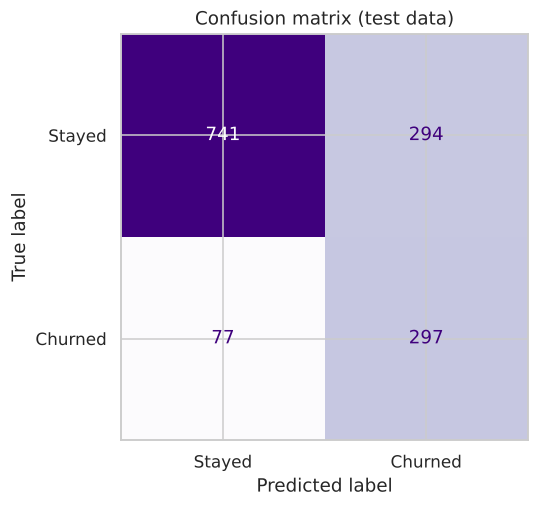

Churners caught (TP):        297
Churners missed (FN):        77
Loyal flagged by mistake (FP): 294
Recall: 79.4%  -> we catch about 79% of customers who leave


In [19]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Purples", colorbar=False)
plt.title("Confusion matrix (test data)"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Churners caught (TP):        {tp}")
print(f"Churners missed (FN):        {fn}")
print(f"Loyal flagged by mistake (FP): {fp}")
print(f"Recall: {tp / (tp + fn):.1%}  -> we catch about {tp / (tp + fn):.0%} of customers who leave")

**Reading the result:** the model catches about **79%** of customers who leave. The price is that some loyal customers are flagged too (precision about 50%). For a retention team this is a good trade: a wrongly flagged customer costs one discount offer, a missed churner costs a whole customer.

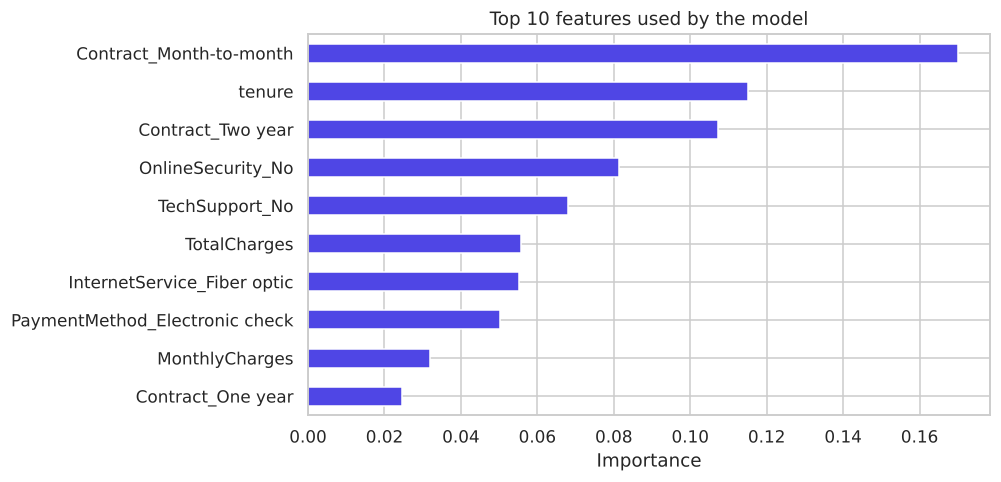

In [20]:
# What does the model look at? Top 10 features
names = best_model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(best_model.named_steps["model"].feature_importances_, index=names)
top = importance.sort_values().tail(10)
top.index = [n.replace("num__", "").replace("cat__", "") for n in top.index]

ax = top.plot(kind="barh", figsize=(8, 4.5), color="#4f46e5")
ax.set_title("Top 10 features used by the model"); ax.set_xlabel("Importance")
plt.show()

In [21]:
# Do the High / Medium / Low risk bands used in the app make sense?
prob = best_model.predict_proba(X_test)[:, 1]
band = pd.cut(prob, [0, 0.35, 0.60, 1.0], labels=["Low", "Medium", "High"])
bands = pd.DataFrame({"Risk": band, "Left": y_test.values}).groupby("Risk", observed=True)["Left"].agg(["count", "mean"])
bands["mean"] = (bands["mean"] * 100).round(1)
bands.columns = ["Customers", "Actual churn rate (%)"]
bands

,Customers,Actual churn rate (%)
Risk,,
Low,613,5.4
Medium,332,23.8
High,464,56.5


The bands separate customers clearly: Low-risk customers rarely leave, High-risk customers leave more than half the time. Because the model is balanced, treat the score as a **ranking of risk**, not an exact probability.

## Step 11: Business recommendations

1. **Move month-to-month customers to longer contracts.** They churn at 43% vs 3% for two-year contracts. Offer a discount or a free upgrade for a 1- or 2-year commitment.
2. **Focus on the first year.** Most churn happens early. Add a welcome call and check-ins at 30, 60 and 90 days, and give new customers extra support.
3. **Move customers away from electronic check.** They churn at 45%. Give a small bill credit for automatic bank or card payment.
4. **Fix the fiber and support gap.** Fiber customers pay more and churn at 42%, and customers without tech support or online security churn more. Review fiber price and quality, and bundle tech support and security at a discount.
5. **Use the app weekly.** Score all customers, and call the High-risk list first with the matching offer.

## Save the final model (optional)
The Streamlit app retrains this same model when it starts, so this file is just a backup.

In [22]:
import joblib
joblib.dump(best_model, "churn_model.joblib")
print("Saved churn_model.joblib")

Saved churn_model.joblib
